# Cluster-Permutation Test: Where Does wCSET Outperform Each Method Across the Noise Sweep?

Exploratory analysis on the existing noise-sweep pilot data (`pilot_noise_outcomes.tsv`,
520 runs x 6 methods x 5 SNR levels) -- no new simulation or solving. Instead of
fitting a slope (which turned out to have real interpretive problems -- see chat
history: a method that front-loads its degradation into the first noise step gets an
artificially shallow slope even if its total degradation is comparable to other
methods'), this asks a more localized, assumption-light question: **at which specific,
contiguous SNR levels does wCSET significantly outperform each other method?**

## Design: region-as-subject cluster permutation

Standard EEG/MEG cluster-permutation logic (Maris & Oostenveld), with **region**
playing the role of **subject** and **SNR level** playing the role of **time**:

- Repetitions aren't matched across SNR levels (each `(region, snr, repetition)` got
  its own independent seed, including the signal-generation jitter -- not just the
  noise), so they can't serve as the permutation unit. **Region can** -- it's the same
  physical region at every SNR level, so any region-specific structure in the
  wCSET-vs-competitor difference persists across the whole sweep.
- For each region, average the paired `wCSET - competitor` difference (sign-flipped
  so positive = wCSET better) over the 4 repetitions at each SNR level -> one 5-point
  series per region, 26 series total.
- Observed statistic: one-sample t-test across the 26 regions' values, at each SNR
  level independently; contiguous levels exceeding the cluster-forming threshold
  become a candidate cluster; cluster mass = summed t-statistic.
- Null distribution: flip each region's **entire series sign** consistently across
  all 5 SNR levels (not independently per level -- that's what makes this a
  *region*-level permutation, respecting the one correlation structure that
  actually exists here), recompute clusters, track the largest cluster mass in each
  direction. Repeat 3000+ times.
- A cluster's p-value = how often the permuted null produces a cluster at least as
  extreme as the observed one.

Run for every `(outcome, competitor)` pair: 4 outcomes x 5 competitors (`cset`, `mce`,
`sloreta`, `dspm`, `mne`) = 20 tests. Cheap -- each permutation is a 26x5 array
operation, thousands of them run in well under a second per test.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
HIGHER_IS_BETTER = {"localization_error_hrp": False, "ap_hrp": True, "ap_pp": True, "correlation_auc": True}
REFERENCE_METHOD = "wcset"
COMPETITORS = ["cset", "mce", "sloreta", "dspm", "mne"]
SNR_ORDER = [20.0, 10.0, 5.0, 2.0, 1.0]   # decreasing SNR = increasing noise; contiguity is defined along this axis
N_PERM = 3000
CLUSTER_ALPHA = 0.05

df = pd.read_csv("pilot_noise_outcomes.tsv", sep="\t")
regions = sorted(df["region"].unique())
k = len(regions)
print(f"{len(df)} rows, {k} regions, snr levels {SNR_ORDER}")

3120 rows, 26 regions, snr levels [20.0, 10.0, 5.0, 2.0, 1.0]


## Helper functions

`region_series` builds the `(k regions, 5 snr levels)` difference matrix for one
`(outcome, competitor)` pair. `cluster_permutation_test` runs the test described
above on that matrix.

In [2]:
def region_series(outcome, competitor):
    """(k, S) matrix: per-region, per-SNR-level mean paired difference (wcset - competitor),
    sign-adjusted so positive = wcset better, averaged over repetitions."""
    sign = 1.0 if HIGHER_IS_BETTER[outcome] else -1.0
    wide_wcset = df[df["method"] == REFERENCE_METHOD].groupby(["region", "snr"])[outcome].mean().unstack()[SNR_ORDER]
    wide_comp = df[df["method"] == competitor].groupby(["region", "snr"])[outcome].mean().unstack()[SNR_ORDER]
    diff = sign * (wide_wcset - wide_comp)
    return diff.reindex(regions).to_numpy()


def cluster_permutation_test(D, cluster_alpha=CLUSTER_ALPHA, n_perm=N_PERM, seed=0):
    """
    D: (k, S) array, one series per region (subject), S = ordered SNR levels.
    Region-level permutation: flips each row's sign consistently across all S columns.
    Returns observed t per level and a list of clusters (start/end SNR, mass, sign, p-value).
    """
    k, S = D.shape
    rng = np.random.default_rng(seed)
    t_crit = stats.t.ppf(1 - cluster_alpha / 2, df=k - 1)

    def compute_t(Dperm):
        m = Dperm.mean(axis=0)
        se = Dperm.std(axis=0, ddof=1) / np.sqrt(k)
        return m / se

    def find_clusters(t):
        clusters = []
        sign_mask = np.where(t > t_crit, 1, np.where(t < -t_crit, -1, 0))
        i = 0
        while i < S:
            if sign_mask[i] != 0:
                j = i
                while j < S and sign_mask[j] == sign_mask[i]:
                    j += 1
                clusters.append((i, j - 1, np.sum(t[i:j]), sign_mask[i]))
                i = j
            else:
                i += 1
        return clusters

    t_obs = compute_t(D)
    clusters_obs = find_clusters(t_obs)

    max_pos_null = np.zeros(n_perm)
    min_neg_null = np.zeros(n_perm)
    for p in range(n_perm):
        flips = rng.choice([-1.0, 1.0], size=k)
        t_p = compute_t(D * flips[:, None])
        clusters_p = find_clusters(t_p)
        pos = [c[2] for c in clusters_p if c[3] == 1]
        neg = [c[2] for c in clusters_p if c[3] == -1]
        max_pos_null[p] = max(pos) if pos else 0.0
        min_neg_null[p] = min(neg) if neg else 0.0

    results = []
    for (i, j, mass, sgn) in clusters_obs:
        pval = ((np.sum(max_pos_null >= mass) + 1) / (n_perm + 1) if sgn == 1
                else (np.sum(min_neg_null <= mass) + 1) / (n_perm + 1))
        results.append({"snr_start": SNR_ORDER[i], "snr_end": SNR_ORDER[j], "mass": mass, "sign": sgn, "p_value": pval})

    return {"t_obs": t_obs, "clusters": results}

## Run all 20 tests (4 outcomes x 5 competitors)

In [3]:
all_results = []
series_cache = {}
for outcome in OUTCOMES:
    for competitor in COMPETITORS:
        D = region_series(outcome, competitor)
        series_cache[(outcome, competitor)] = D
        seed = abs(hash((outcome, competitor))) % (2**31)
        res = cluster_permutation_test(D, seed=seed)
        if res["clusters"]:
            for c in res["clusters"]:
                all_results.append({"outcome": outcome, "competitor": competitor, **c})
        else:
            all_results.append({"outcome": outcome, "competitor": competitor,
                                 "snr_start": None, "snr_end": None, "mass": None, "sign": None, "p_value": None})

results_df = pd.DataFrame(all_results)
results_df.to_csv("pilot_noise_cluster_permutation_results.tsv", sep="\t", index=False)
pd.set_option("display.width", 160)
results_df

,outcome,competitor,snr_start,snr_end,mass,sign,p_value
0,localization_error_hrp,cset,20.0,20.0,4.067421,1,0.009997
1,localization_error_hrp,cset,2.0,2.0,3.418088,1,0.013329
2,localization_error_hrp,mce,20.0,10.0,10.040112,1,0.000333
3,localization_error_hrp,sloreta,20.0,20.0,4.145544,1,0.007997
4,localization_error_hrp,sloreta,5.0,1.0,7.397861,1,0.000666
5,localization_error_hrp,dspm,20.0,20.0,4.552952,1,0.010663
6,localization_error_hrp,dspm,5.0,2.0,-6.586389,-1,0.003332
7,localization_error_hrp,mne,20.0,1.0,37.218442,1,0.000333
8,ap_hrp,cset,20.0,1.0,24.983398,1,0.000333
9,ap_hrp,mce,20.0,1.0,56.497560,1,0.000333


## Significant clusters only (p < 0.05), wCSET-favoring vs. competitor-favoring separated

In [4]:
sig = results_df[results_df["p_value"] < 0.05].copy()
sig["direction"] = sig["sign"].map({1: "wCSET better", -1: "competitor better"})
sig[["outcome", "competitor", "direction", "snr_start", "snr_end", "mass", "p_value"]].sort_values(["outcome", "competitor"])

,outcome,competitor,direction,snr_start,snr_end,mass,p_value
8,ap_hrp,cset,wCSET better,20.0,1.0,24.983398,0.000333
11,ap_hrp,dspm,wCSET better,20.0,1.0,27.739027,0.000333
9,ap_hrp,mce,wCSET better,20.0,1.0,56.497560,0.000333
12,ap_hrp,mne,wCSET better,20.0,1.0,45.097505,0.000333
10,ap_hrp,sloreta,wCSET better,20.0,1.0,31.254613,0.000333
13,ap_pp,cset,wCSET better,20.0,1.0,21.100039,0.000333
16,ap_pp,dspm,wCSET better,20.0,1.0,21.544160,0.000333
14,ap_pp,mce,wCSET better,20.0,1.0,31.058050,0.000333
17,ap_pp,mne,wCSET better,20.0,1.0,28.978480,0.000333
15,ap_pp,sloreta,wCSET better,20.0,1.0,23.137720,0.000333


## Difference series per outcome, with significant SNR ranges shaded

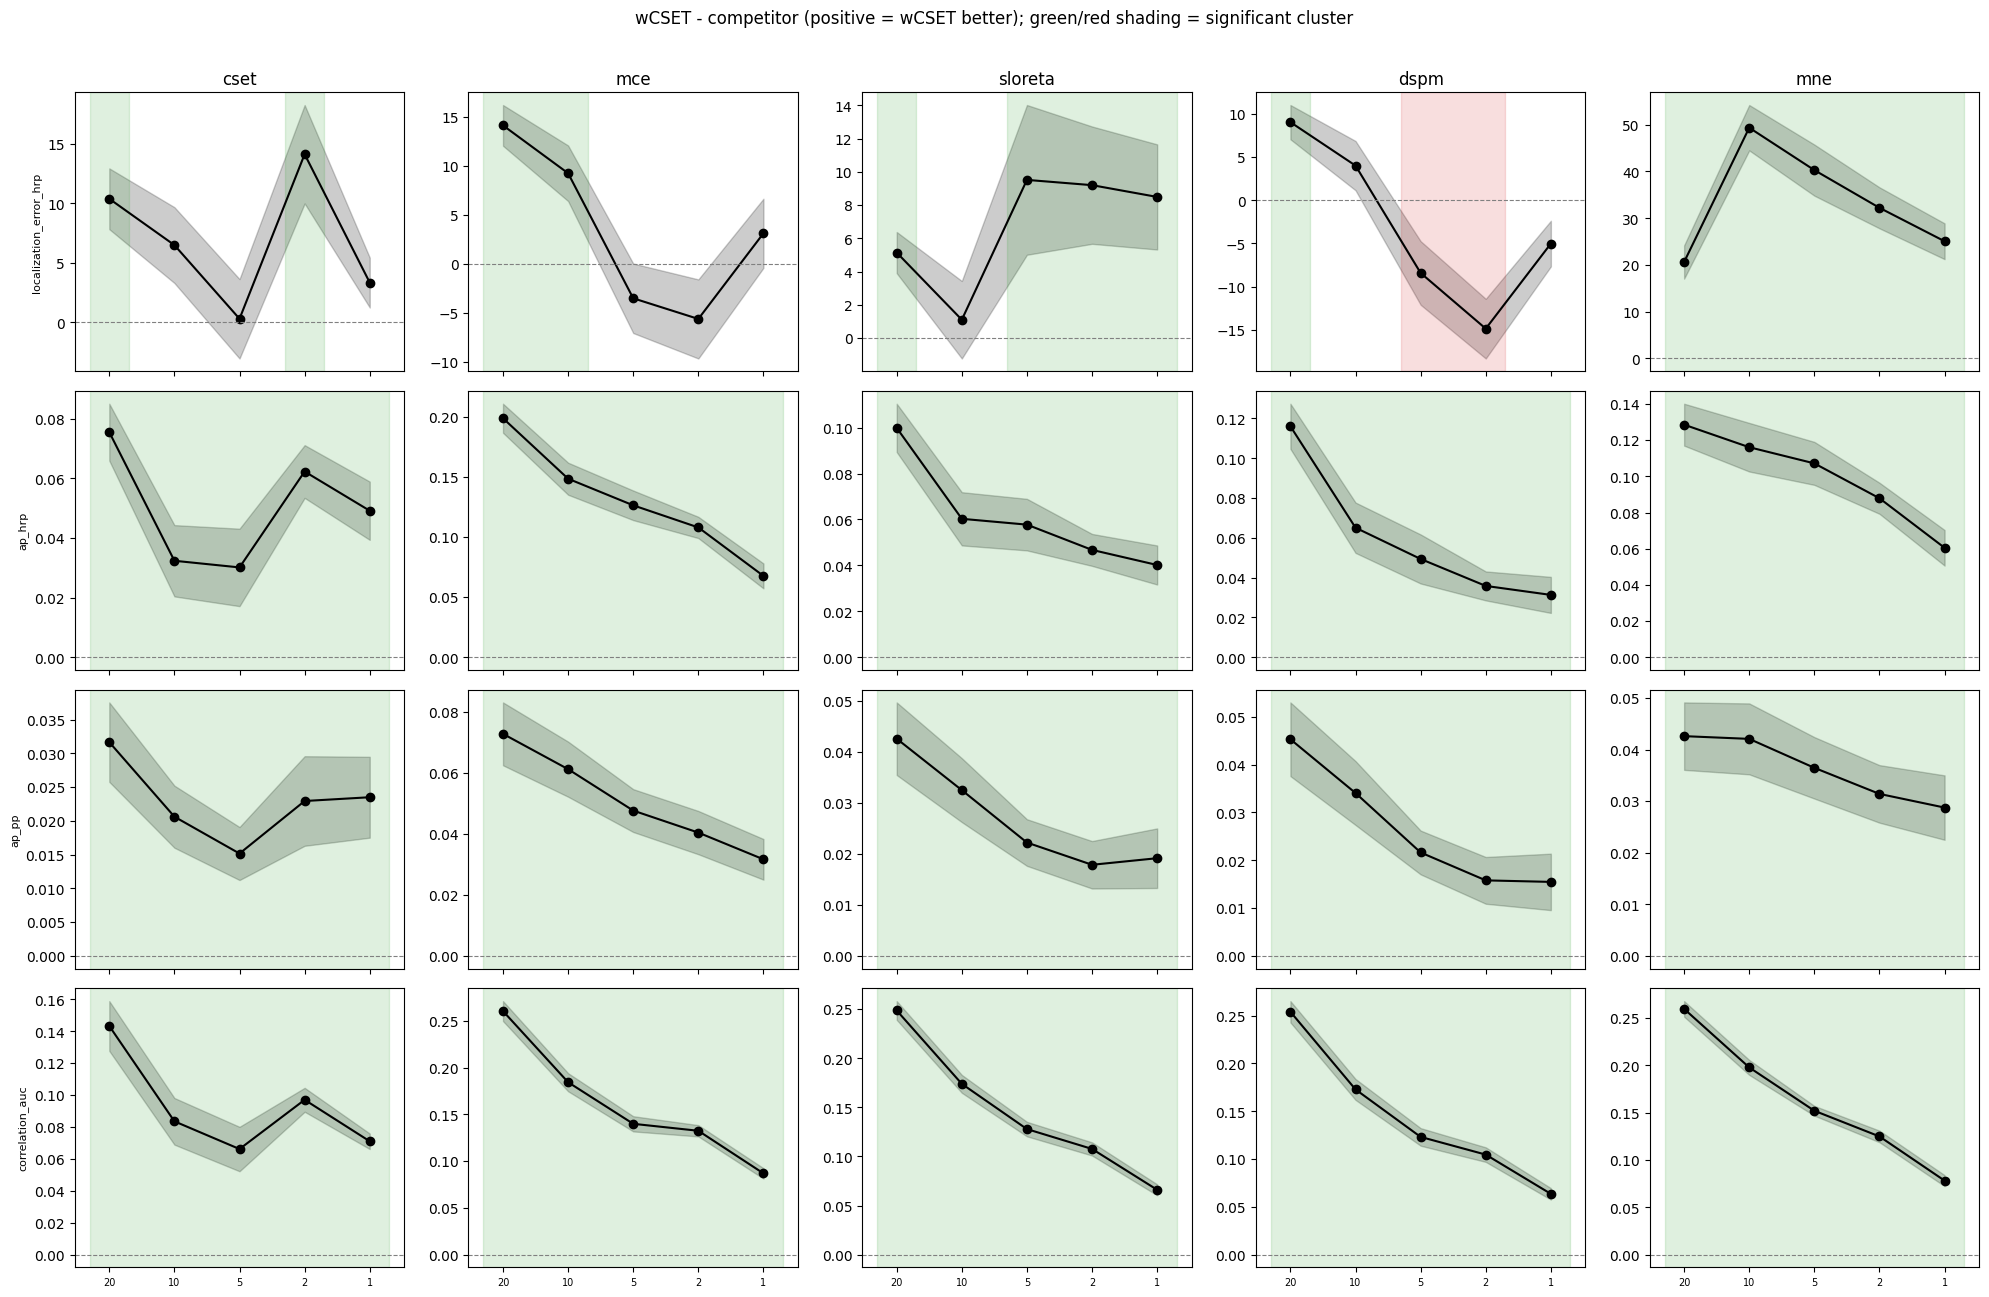

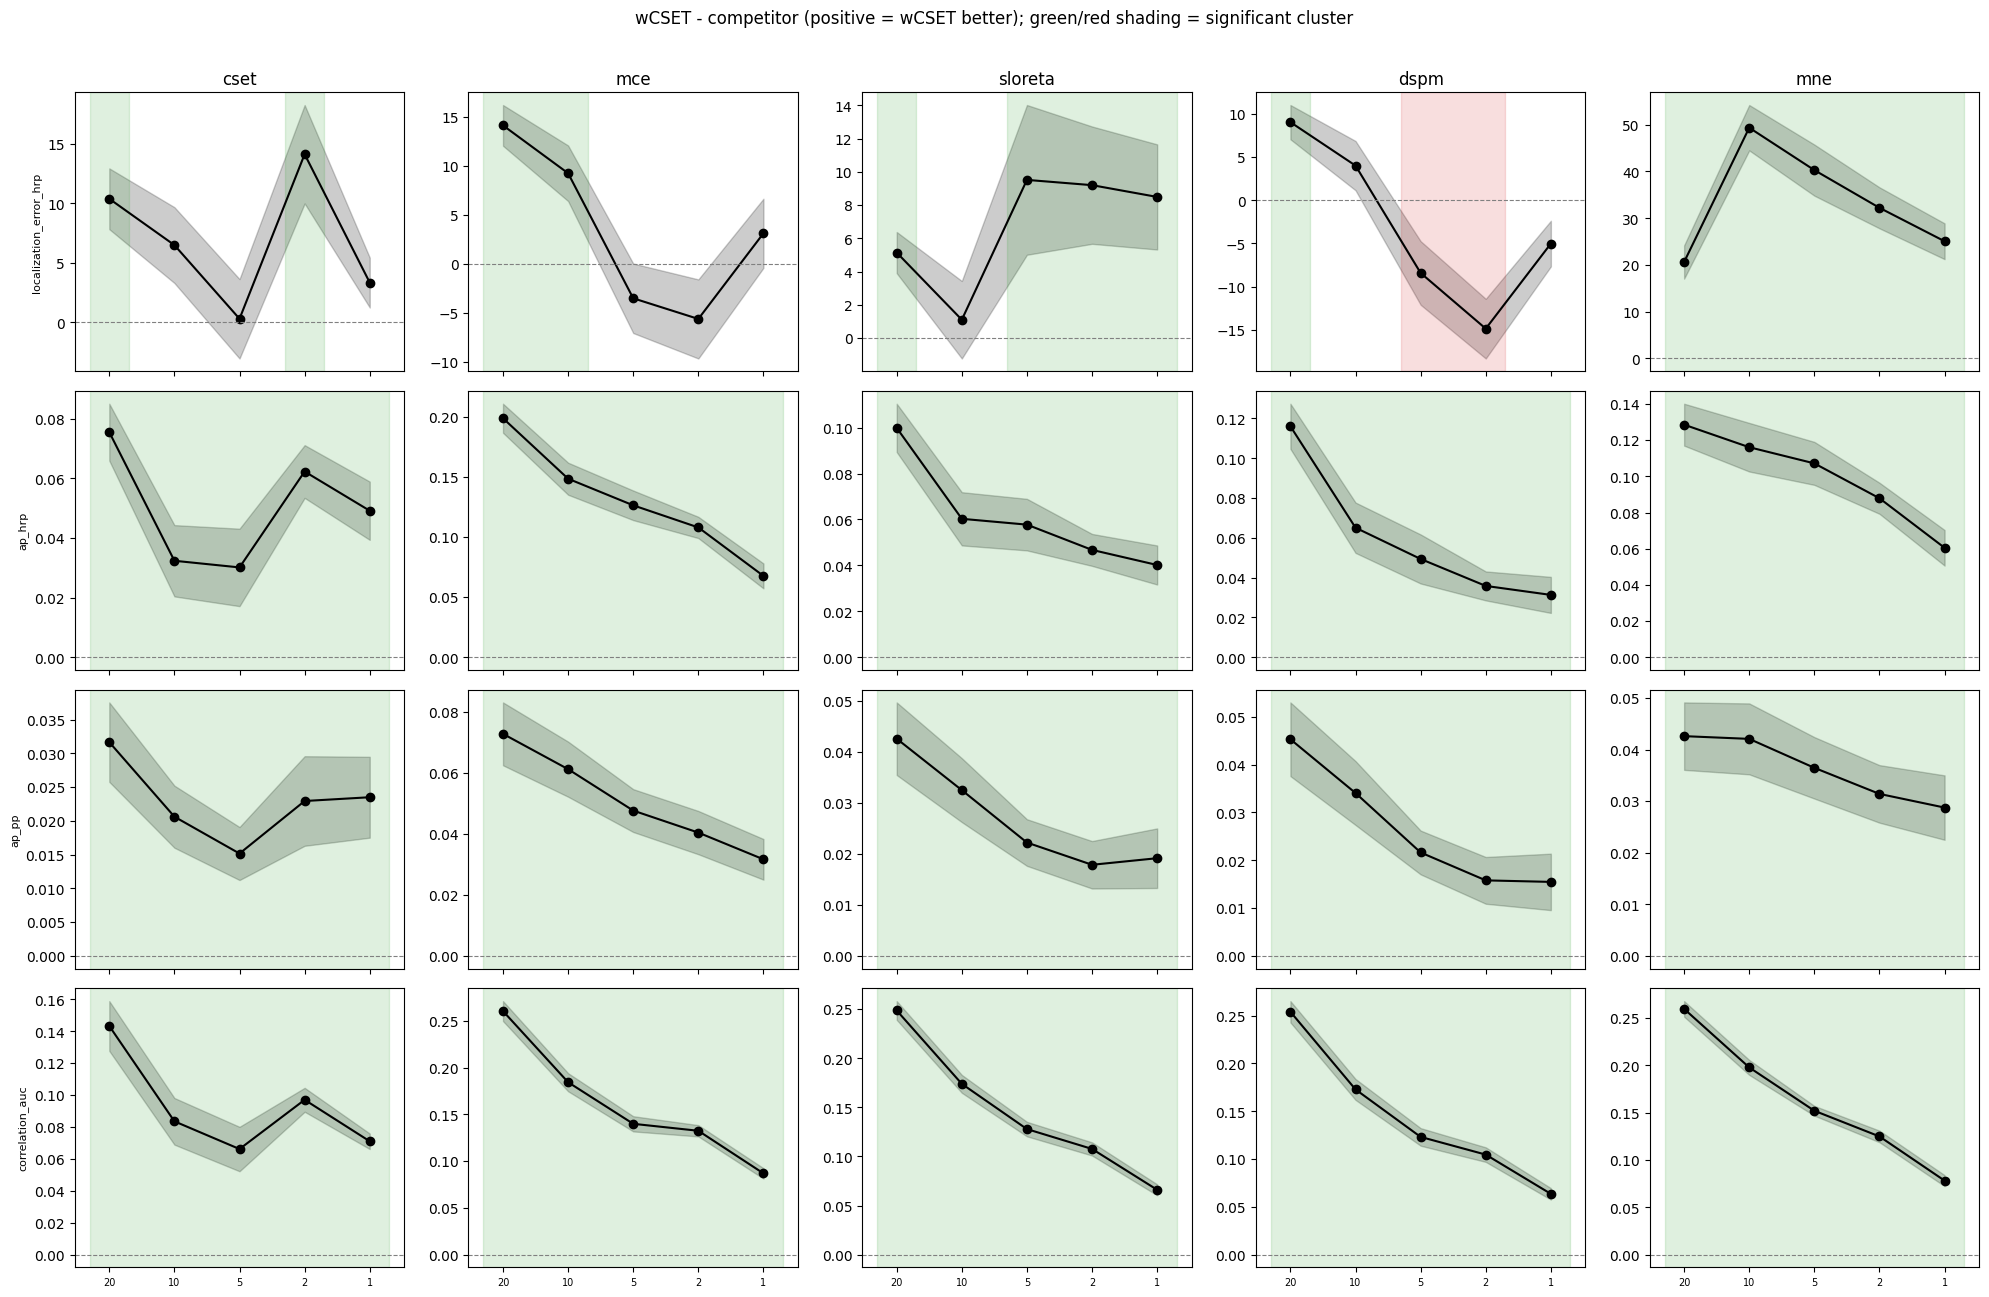

In [5]:
fig, axes = plt.subplots(len(OUTCOMES), len(COMPETITORS), figsize=(4 * len(COMPETITORS), 3.2 * len(OUTCOMES)), sharex=True)
for oi, outcome in enumerate(OUTCOMES):
    for ci, competitor in enumerate(COMPETITORS):
        ax = axes[oi, ci]
        D = series_cache[(outcome, competitor)]
        mean_series = D.mean(axis=0)
        se_series = D.std(axis=0, ddof=1) / np.sqrt(k)
        x = np.arange(len(SNR_ORDER))
        ax.plot(x, mean_series, marker="o", color="black")
        ax.fill_between(x, mean_series - se_series, mean_series + se_series, alpha=0.2, color="black")
        ax.axhline(0, ls="--", c="gray", lw=0.8)

        rows = results_df[(results_df["outcome"] == outcome) & (results_df["competitor"] == competitor) & (results_df["p_value"] < 0.05)]
        for _, row in rows.iterrows():
            i = SNR_ORDER.index(row["snr_start"]); j = SNR_ORDER.index(row["snr_end"])
            color = "tab:green" if row["sign"] == 1 else "tab:red"
            ax.axvspan(i - 0.3, j + 0.3, color=color, alpha=0.15)

        if oi == 0:
            ax.set_title(competitor)
        if ci == 0:
            ax.set_ylabel(outcome, fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels([str(int(s)) for s in SNR_ORDER], fontsize=7)

fig.suptitle("wCSET - competitor (positive = wCSET better); green/red shading = significant cluster", y=1.01)
fig.tight_layout()
fig.savefig("pilot_noise_cluster_permutation_curves.png", dpi=130, bbox_inches="tight")
fig

## Reading the result

Each panel is one `(outcome, competitor)` pair's difference series across the SNR
sweep (x-axis: SNR from 20 down to 1). Green shading = a contiguous SNR range where
wCSET is significantly better; red = where the competitor is significantly better.
No shading = no significant cluster found there -- absence of evidence, not evidence
that they're equal, especially for shorter/noisier stretches.